In [2]:
# !pip install torchvision

In [1]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

In [2]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths for all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [3]:
root_dir_path = "./img_align_celeba"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [4]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 202599 images


In [5]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

## Generator Network

In [6]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [7]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512), 
            nn.ReLU(),

            nn.Linear(512, 1024), 
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels), 
            nn.Tanh() # [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64) 
        return img

        # fake img => 64 x 64 x 3 x batch_size

## Discriminator Network

In [8]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3): # 3 is for RGB
        super(Discriminator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor => 1D
            
            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), 
            nn.Sigmoid() # probability of being real/fake 
        )

    def forward(self, img):
        return self.model(img)

In [9]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [10]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")

device is mps


In [11]:
generator = generator.to(device)
discriminator = discriminator.to(device)

## Training the GAN

In [12]:
def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device) 

In [13]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/15... batch: 1... G-loss:1.469368815422058.... D-loss: 0.5408632159233093
for epoch: 1/15... batch: 51... G-loss:1.5084465742111206.... D-loss: 0.49146056175231934
for epoch: 1/15... batch: 101... G-loss:1.5122745037078857.... D-loss: 0.579361617565155
for epoch: 1/15... batch: 151... G-loss:1.579174280166626.... D-loss: 0.5709105730056763
for epoch: 1/15... batch: 201... G-loss:1.4521816968917847.... D-loss: 0.532662034034729
for epoch: 1/15... batch: 251... G-loss:1.5025290250778198.... D-loss: 0.5845669507980347
for epoch: 1/15... batch: 301... G-loss:1.4498584270477295.... D-loss: 0.541619062423706
for epoch: 1/15... batch: 351... G-loss:1.5876853466033936.... D-loss: 0.5133283138275146
for epoch: 1/15... batch: 401... G-loss:1.4606072902679443.... D-loss: 0.5642707347869873
for epoch: 1/15... batch: 451... G-loss:1.4710078239440918.... D-loss: 0.5813220143318176
for epoch: 1/15... batch: 501... G-loss:1.476613998413086.... D-loss: 0.5522395372390747
for epoch: 1/15...

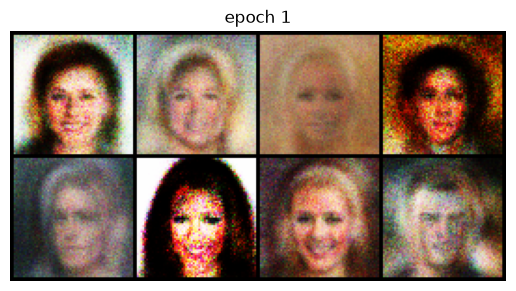

for epoch: 2/15... batch: 1... G-loss:1.479296326637268.... D-loss: 0.6304276585578918
for epoch: 2/15... batch: 51... G-loss:1.5910711288452148.... D-loss: 0.551800012588501
for epoch: 2/15... batch: 101... G-loss:1.5563228130340576.... D-loss: 0.5986298322677612
for epoch: 2/15... batch: 151... G-loss:1.5624171495437622.... D-loss: 0.6613646745681763
for epoch: 2/15... batch: 201... G-loss:1.336596965789795.... D-loss: 0.6029932498931885
for epoch: 2/15... batch: 251... G-loss:1.4767851829528809.... D-loss: 0.5898559093475342
for epoch: 2/15... batch: 301... G-loss:1.4701730012893677.... D-loss: 0.5167310237884521
for epoch: 2/15... batch: 351... G-loss:1.819956660270691.... D-loss: 0.6449764370918274
for epoch: 2/15... batch: 401... G-loss:1.4304277896881104.... D-loss: 0.5730646848678589
for epoch: 2/15... batch: 451... G-loss:1.6500811576843262.... D-loss: 0.5463461875915527
for epoch: 2/15... batch: 501... G-loss:1.4365427494049072.... D-loss: 0.5706846117973328
for epoch: 2/15..

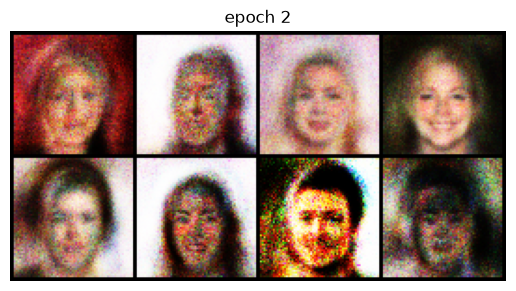

for epoch: 3/15... batch: 1... G-loss:1.4658679962158203.... D-loss: 0.5237843990325928
for epoch: 3/15... batch: 51... G-loss:1.3324989080429077.... D-loss: 0.5444568395614624
for epoch: 3/15... batch: 101... G-loss:1.1618098020553589.... D-loss: 0.6155716180801392
for epoch: 3/15... batch: 151... G-loss:1.4044100046157837.... D-loss: 0.5351342558860779
for epoch: 3/15... batch: 201... G-loss:1.2375662326812744.... D-loss: 0.5556035041809082
for epoch: 3/15... batch: 251... G-loss:1.2014296054840088.... D-loss: 0.6113646030426025
for epoch: 3/15... batch: 301... G-loss:1.1741013526916504.... D-loss: 0.6027208566665649
for epoch: 3/15... batch: 351... G-loss:1.2820228338241577.... D-loss: 0.5735841393470764
for epoch: 3/15... batch: 401... G-loss:1.2432708740234375.... D-loss: 0.5962691307067871
for epoch: 3/15... batch: 451... G-loss:1.2638871669769287.... D-loss: 0.5294134616851807
for epoch: 3/15... batch: 501... G-loss:1.263839602470398.... D-loss: 0.565475583076477
for epoch: 3/15

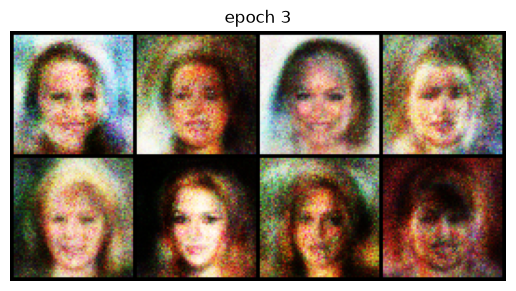

for epoch: 4/15... batch: 1... G-loss:1.3840986490249634.... D-loss: 0.6120284199714661
for epoch: 4/15... batch: 51... G-loss:1.3113727569580078.... D-loss: 0.5333408117294312
for epoch: 4/15... batch: 101... G-loss:1.1186017990112305.... D-loss: 0.6061743497848511
for epoch: 4/15... batch: 151... G-loss:1.221459150314331.... D-loss: 0.5970093607902527
for epoch: 4/15... batch: 201... G-loss:1.2930989265441895.... D-loss: 0.5581936240196228
for epoch: 4/15... batch: 251... G-loss:1.3173725605010986.... D-loss: 0.6256105899810791
for epoch: 4/15... batch: 301... G-loss:1.2641229629516602.... D-loss: 0.5655609965324402
for epoch: 4/15... batch: 351... G-loss:1.1724212169647217.... D-loss: 0.5667479038238525
for epoch: 4/15... batch: 401... G-loss:1.168105125427246.... D-loss: 0.5878392457962036
for epoch: 4/15... batch: 451... G-loss:1.2661800384521484.... D-loss: 0.6328579783439636
for epoch: 4/15... batch: 501... G-loss:1.214491605758667.... D-loss: 0.5800596475601196
for epoch: 4/15.

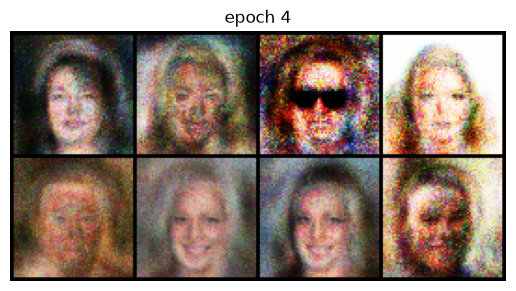

for epoch: 5/15... batch: 1... G-loss:1.2598865032196045.... D-loss: 0.6521314978599548
for epoch: 5/15... batch: 51... G-loss:1.147714614868164.... D-loss: 0.5852333307266235
for epoch: 5/15... batch: 101... G-loss:1.1261212825775146.... D-loss: 0.5744332671165466
for epoch: 5/15... batch: 151... G-loss:1.2116520404815674.... D-loss: 0.6098086833953857
for epoch: 5/15... batch: 201... G-loss:1.2615063190460205.... D-loss: 0.5781087875366211
for epoch: 5/15... batch: 251... G-loss:1.1359961032867432.... D-loss: 0.551882266998291
for epoch: 5/15... batch: 301... G-loss:1.161023497581482.... D-loss: 0.6452314853668213
for epoch: 5/15... batch: 351... G-loss:1.2986156940460205.... D-loss: 0.5331010818481445
for epoch: 5/15... batch: 401... G-loss:1.355949878692627.... D-loss: 0.6215317249298096
for epoch: 5/15... batch: 451... G-loss:1.2283960580825806.... D-loss: 0.5837274789810181
for epoch: 5/15... batch: 501... G-loss:1.1357967853546143.... D-loss: 0.6222702264785767
for epoch: 5/15..

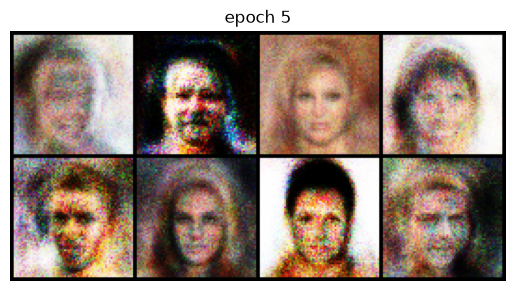

for epoch: 6/15... batch: 1... G-loss:1.0359010696411133.... D-loss: 0.6151095628738403
for epoch: 6/15... batch: 51... G-loss:1.167237401008606.... D-loss: 0.613422155380249
for epoch: 6/15... batch: 101... G-loss:1.0750774145126343.... D-loss: 0.6204297542572021
for epoch: 6/15... batch: 151... G-loss:1.1306782960891724.... D-loss: 0.6614920496940613
for epoch: 6/15... batch: 201... G-loss:1.2518842220306396.... D-loss: 0.6154738664627075
for epoch: 6/15... batch: 251... G-loss:1.1043696403503418.... D-loss: 0.6083338260650635
for epoch: 6/15... batch: 301... G-loss:1.1765817403793335.... D-loss: 0.5840796232223511
for epoch: 6/15... batch: 351... G-loss:1.2088427543640137.... D-loss: 0.6067308187484741
for epoch: 6/15... batch: 401... G-loss:1.1009162664413452.... D-loss: 0.6180616021156311
for epoch: 6/15... batch: 451... G-loss:1.2339661121368408.... D-loss: 0.6370333433151245
for epoch: 6/15... batch: 501... G-loss:1.281543254852295.... D-loss: 0.578680157661438
for epoch: 6/15..

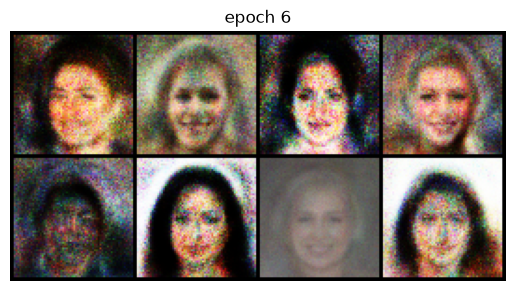

for epoch: 7/15... batch: 1... G-loss:1.2258989810943604.... D-loss: 0.5627613067626953
for epoch: 7/15... batch: 51... G-loss:1.1115832328796387.... D-loss: 0.5833775997161865
for epoch: 7/15... batch: 101... G-loss:1.086566686630249.... D-loss: 0.6150288581848145
for epoch: 7/15... batch: 151... G-loss:1.1928292512893677.... D-loss: 0.6485646367073059
for epoch: 7/15... batch: 201... G-loss:1.0558196306228638.... D-loss: 0.6290116906166077
for epoch: 7/15... batch: 251... G-loss:1.2317146062850952.... D-loss: 0.610576868057251
for epoch: 7/15... batch: 301... G-loss:1.1270759105682373.... D-loss: 0.6455501317977905
for epoch: 7/15... batch: 351... G-loss:1.1581491231918335.... D-loss: 0.6015284061431885
for epoch: 7/15... batch: 401... G-loss:1.2275290489196777.... D-loss: 0.5889763832092285
for epoch: 7/15... batch: 451... G-loss:1.2452137470245361.... D-loss: 0.623972475528717
for epoch: 7/15... batch: 501... G-loss:1.0497820377349854.... D-loss: 0.6163599491119385
for epoch: 7/15.

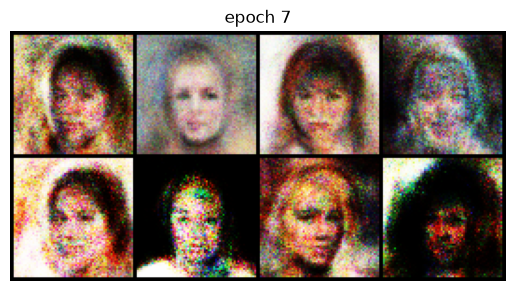

for epoch: 8/15... batch: 1... G-loss:1.146608829498291.... D-loss: 0.5861330032348633
for epoch: 8/15... batch: 51... G-loss:1.0877948999404907.... D-loss: 0.6343163251876831
for epoch: 8/15... batch: 101... G-loss:1.1387181282043457.... D-loss: 0.6196905374526978
for epoch: 8/15... batch: 151... G-loss:1.0930140018463135.... D-loss: 0.5816909074783325
for epoch: 8/15... batch: 201... G-loss:1.0313258171081543.... D-loss: 0.5921516418457031
for epoch: 8/15... batch: 251... G-loss:1.2171580791473389.... D-loss: 0.6164587140083313
for epoch: 8/15... batch: 301... G-loss:0.9949392080307007.... D-loss: 0.6238319873809814
for epoch: 8/15... batch: 351... G-loss:1.0455234050750732.... D-loss: 0.5842857360839844
for epoch: 8/15... batch: 401... G-loss:1.133547067642212.... D-loss: 0.7098175883293152
for epoch: 8/15... batch: 451... G-loss:1.0943506956100464.... D-loss: 0.5920080542564392
for epoch: 8/15... batch: 501... G-loss:1.0418856143951416.... D-loss: 0.5985831022262573
for epoch: 8/15

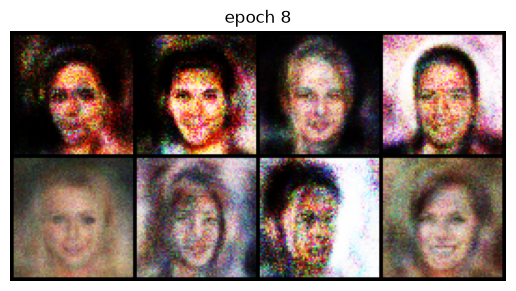

for epoch: 9/15... batch: 1... G-loss:1.0367584228515625.... D-loss: 0.6382184028625488
for epoch: 9/15... batch: 51... G-loss:1.1485576629638672.... D-loss: 0.5943889617919922
for epoch: 9/15... batch: 101... G-loss:1.0690524578094482.... D-loss: 0.6126692295074463
for epoch: 9/15... batch: 151... G-loss:1.118830680847168.... D-loss: 0.6094493269920349
for epoch: 9/15... batch: 201... G-loss:1.0738880634307861.... D-loss: 0.6263628005981445
for epoch: 9/15... batch: 251... G-loss:1.1455280780792236.... D-loss: 0.6104519367218018
for epoch: 9/15... batch: 301... G-loss:1.0813729763031006.... D-loss: 0.6094626188278198
for epoch: 9/15... batch: 351... G-loss:1.0670322179794312.... D-loss: 0.6492780447006226
for epoch: 9/15... batch: 401... G-loss:1.145171046257019.... D-loss: 0.6362574100494385
for epoch: 9/15... batch: 451... G-loss:1.2031195163726807.... D-loss: 0.6228955984115601
for epoch: 9/15... batch: 501... G-loss:1.1486386060714722.... D-loss: 0.575812578201294
for epoch: 9/15.

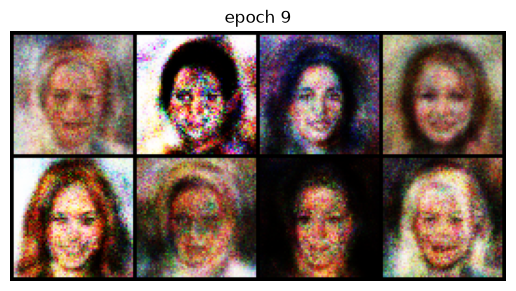

for epoch: 10/15... batch: 1... G-loss:1.0736554861068726.... D-loss: 0.6108533143997192
for epoch: 10/15... batch: 51... G-loss:1.005969762802124.... D-loss: 0.6449726819992065
for epoch: 10/15... batch: 101... G-loss:1.038407325744629.... D-loss: 0.6218935251235962
for epoch: 10/15... batch: 151... G-loss:1.1188527345657349.... D-loss: 0.6560924649238586
for epoch: 10/15... batch: 201... G-loss:1.024469017982483.... D-loss: 0.6027663350105286
for epoch: 10/15... batch: 251... G-loss:1.1237733364105225.... D-loss: 0.6346871256828308
for epoch: 10/15... batch: 301... G-loss:1.1961472034454346.... D-loss: 0.6136411428451538
for epoch: 10/15... batch: 351... G-loss:1.0421433448791504.... D-loss: 0.6020695567131042
for epoch: 10/15... batch: 401... G-loss:1.1524475812911987.... D-loss: 0.6162554025650024
for epoch: 10/15... batch: 451... G-loss:1.1296617984771729.... D-loss: 0.6188219785690308
for epoch: 10/15... batch: 501... G-loss:1.1494371891021729.... D-loss: 0.6056200265884399
for e

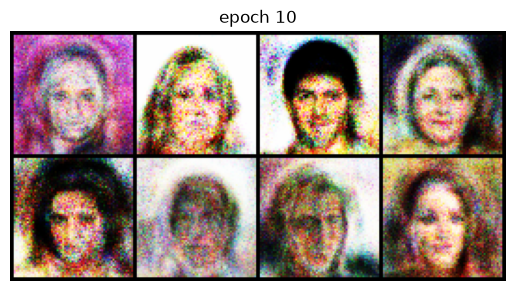

for epoch: 11/15... batch: 1... G-loss:1.052100658416748.... D-loss: 0.605728030204773
for epoch: 11/15... batch: 51... G-loss:1.1851085424423218.... D-loss: 0.6605046987533569
for epoch: 11/15... batch: 101... G-loss:1.0226068496704102.... D-loss: 0.5823312401771545
for epoch: 11/15... batch: 151... G-loss:1.2266379594802856.... D-loss: 0.5873414278030396
for epoch: 11/15... batch: 201... G-loss:1.1881749629974365.... D-loss: 0.6250232458114624
for epoch: 11/15... batch: 251... G-loss:1.051011562347412.... D-loss: 0.5974873304367065
for epoch: 11/15... batch: 301... G-loss:1.09089994430542.... D-loss: 0.6262933015823364
for epoch: 11/15... batch: 351... G-loss:1.201056957244873.... D-loss: 0.6132296323776245
for epoch: 11/15... batch: 401... G-loss:1.0970356464385986.... D-loss: 0.6607455611228943
for epoch: 11/15... batch: 451... G-loss:1.1790745258331299.... D-loss: 0.6169201135635376
for epoch: 11/15... batch: 501... G-loss:1.1639010906219482.... D-loss: 0.6147130727767944
for epoc

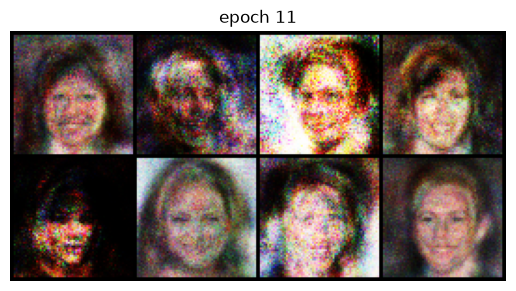

for epoch: 12/15... batch: 1... G-loss:1.0375308990478516.... D-loss: 0.6089577674865723
for epoch: 12/15... batch: 51... G-loss:1.0626640319824219.... D-loss: 0.6210732460021973
for epoch: 12/15... batch: 101... G-loss:1.1142979860305786.... D-loss: 0.581146776676178
for epoch: 12/15... batch: 151... G-loss:1.0920313596725464.... D-loss: 0.5605469346046448
for epoch: 12/15... batch: 201... G-loss:1.0800302028656006.... D-loss: 0.6374477744102478
for epoch: 12/15... batch: 251... G-loss:1.135986328125.... D-loss: 0.5786228179931641
for epoch: 12/15... batch: 301... G-loss:1.0686683654785156.... D-loss: 0.6260663866996765
for epoch: 12/15... batch: 351... G-loss:1.0700645446777344.... D-loss: 0.631458044052124
for epoch: 12/15... batch: 401... G-loss:1.0182560682296753.... D-loss: 0.6024523973464966
for epoch: 12/15... batch: 451... G-loss:1.132738709449768.... D-loss: 0.660551905632019
for epoch: 12/15... batch: 501... G-loss:1.0573909282684326.... D-loss: 0.634229302406311
for epoch: 

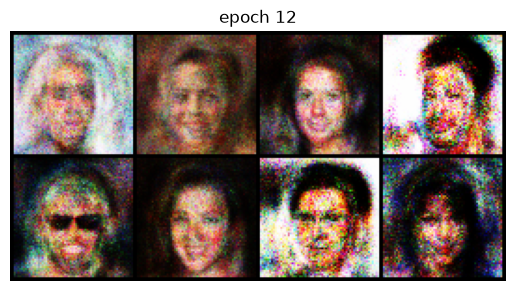

for epoch: 13/15... batch: 1... G-loss:1.0478198528289795.... D-loss: 0.6240146160125732
for epoch: 13/15... batch: 51... G-loss:1.0737714767456055.... D-loss: 0.5630612373352051
for epoch: 13/15... batch: 101... G-loss:1.1617629528045654.... D-loss: 0.5850616693496704
for epoch: 13/15... batch: 151... G-loss:1.160489559173584.... D-loss: 0.559978187084198
for epoch: 13/15... batch: 201... G-loss:1.155036211013794.... D-loss: 0.6309601068496704
for epoch: 13/15... batch: 251... G-loss:1.1264668703079224.... D-loss: 0.6530239582061768
for epoch: 13/15... batch: 301... G-loss:1.156113624572754.... D-loss: 0.605526864528656
for epoch: 13/15... batch: 351... G-loss:1.1454730033874512.... D-loss: 0.6089367270469666
for epoch: 13/15... batch: 401... G-loss:0.9949966073036194.... D-loss: 0.6037313938140869
for epoch: 13/15... batch: 451... G-loss:1.0657167434692383.... D-loss: 0.6084786653518677
for epoch: 13/15... batch: 501... G-loss:1.06758451461792.... D-loss: 0.621097207069397
for epoch:

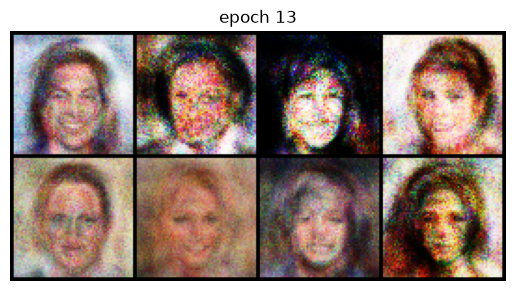

for epoch: 14/15... batch: 1... G-loss:1.1378141641616821.... D-loss: 0.5939472913742065
for epoch: 14/15... batch: 51... G-loss:1.1687393188476562.... D-loss: 0.5874767303466797
for epoch: 14/15... batch: 101... G-loss:1.2770949602127075.... D-loss: 0.6270387172698975
for epoch: 14/15... batch: 151... G-loss:1.0906462669372559.... D-loss: 0.603237509727478
for epoch: 14/15... batch: 201... G-loss:1.1962857246398926.... D-loss: 0.5791186094284058
for epoch: 14/15... batch: 251... G-loss:1.1111993789672852.... D-loss: 0.6078050136566162
for epoch: 14/15... batch: 301... G-loss:1.1331696510314941.... D-loss: 0.5864418745040894
for epoch: 14/15... batch: 351... G-loss:1.0817129611968994.... D-loss: 0.5945456027984619
for epoch: 14/15... batch: 401... G-loss:1.1462470293045044.... D-loss: 0.5666143894195557
for epoch: 14/15... batch: 451... G-loss:1.0338035821914673.... D-loss: 0.6256746053695679
for epoch: 14/15... batch: 501... G-loss:1.0768928527832031.... D-loss: 0.5966446399688721
for

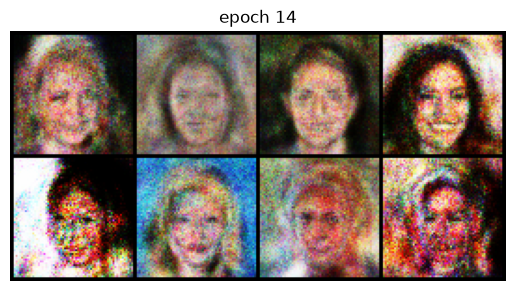

for epoch: 15/15... batch: 1... G-loss:1.1137118339538574.... D-loss: 0.5574061274528503
for epoch: 15/15... batch: 51... G-loss:0.9861019849777222.... D-loss: 0.6224764585494995
for epoch: 15/15... batch: 101... G-loss:1.1032944917678833.... D-loss: 0.6026867628097534
for epoch: 15/15... batch: 151... G-loss:1.09981369972229.... D-loss: 0.5810378193855286
for epoch: 15/15... batch: 201... G-loss:1.1849408149719238.... D-loss: 0.6196178197860718
for epoch: 15/15... batch: 251... G-loss:1.0823760032653809.... D-loss: 0.6528838872909546
for epoch: 15/15... batch: 301... G-loss:1.0785679817199707.... D-loss: 0.6799238324165344
for epoch: 15/15... batch: 351... G-loss:1.1600364446640015.... D-loss: 0.6033043265342712
for epoch: 15/15... batch: 401... G-loss:1.0905951261520386.... D-loss: 0.5810185670852661
for epoch: 15/15... batch: 451... G-loss:1.129805088043213.... D-loss: 0.6270350217819214
for epoch: 15/15... batch: 501... G-loss:1.0590860843658447.... D-loss: 0.602006196975708
for ep

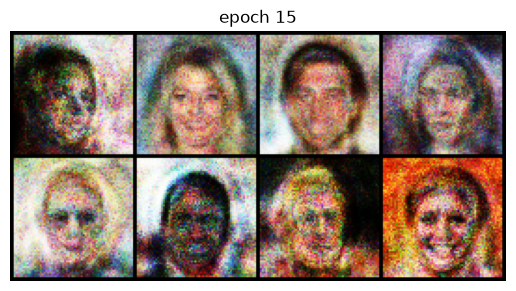

In [15]:
train(generator, discriminator, dataloader, epochs=15)